# Cleaning Canada's Immigration Application Processing Times (Nov 2021 – Jul 2023)
### Phase 2 (Silver) – Data Wrangling

**Author:** Shahil Rai (A00465370)

**Data source:** "Canada Visa Processing Time (last updated July 23)" dataset by user *ayraza* on Kaggle, file `processed_cic_data.csv` ([link](https://www.kaggle.com/datasets/ayraza/canada-visa-processing-time-last-updated-july-23?select=processed_cic_data.csv)). See the References section at the end.

**Goal:** The raw data lists how long Immigration, Refugees and Citizenship Canada (IRCC, formerly "CIC") says it takes to process different applications (visitor visas, study permits, work permits, etc.) for people from each country, recorded on many dates. The raw file is messy. In this notebook I clean it, add some useful new columns, check the result, and save two tidy datasets that are ready for analysis.

**Notebook outline:** 1. Title · 2. Data Acquisition · 3. Initial Exploration · 4. Data Cleaning · 5. Data Enrichment · 6. Validation Checks · 7. Final Analytical Dataset

## 2. Data Acquisition
The data comes from the Kaggle dataset listed in the References section at the end (file `processed_cic_data.csv`). First I import the libraries I need and load the raw CSV file *without changing anything*, so we can see how messy it is.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

raw = pd.read_csv("processed_cic_data.csv")
print("Rows and columns:", raw.shape)

Rows and columns: (184800, 6)


In [2]:
# The first 10 rows, exactly as they came in
display(raw.head(10))

,type,lastupdated,country,processing_time,sponsor_time,refugee_time
0,visitor-outside-canada,2022-11-22,Afghanistan,173 days,NaN,NaN
1,supervisa,2022-11-22,Afghanistan,180 days,NaN,NaN
2,study,2022-11-22,Afghanistan,12 weeks,NaN,NaN
3,work,2022-11-22,Afghanistan,17 weeks,NaN,NaN
4,child_dependent,2022-11-22,Afghanistan,NaN,NaN,NaN
5,child_adopted,2022-11-22,Afghanistan,NaN,NaN,NaN
6,refugees_gov,2022-11-22,Afghanistan,Not enough data,NaN,NaN
7,refugees_private,2022-11-22,Afghanistan,NaN,NaN,NaN
8,visitor-outside-canada,2022-11-22,Albania,190 days,NaN,NaN
9,supervisa,2022-11-22,Albania,180 days,NaN,NaN


In [3]:
# A few examples of "dirty" rows
print("Country names with strange HTML symbols (&rsquo;):")
display(raw[raw["country"].str.contains("&")].drop_duplicates("country"))

print("Rows where the time is a message instead of a number:")
display(raw[raw["processing_time"] == "Not enough data"].head(3))

print("Rows for private refugee sponsorship use different columns:")
display(raw[(raw["type"] == "refugees_private") & raw["sponsor_time"].notna()].head(3))

Country names with strange HTML symbols (&rsquo;):


,type,lastupdated,country,processing_time,sponsor_time,refugee_time
328,visitor-outside-canada,2022-11-22,China (People&rsquo;s Republic of),111 days,NaN,NaN
368,visitor-outside-canada,2022-11-22,Côte d&rsquo;Ivoire,162 days,NaN,NaN


Rows where the time is a message instead of a number:


,type,lastupdated,country,processing_time,sponsor_time,refugee_time
6,refugees_gov,2022-11-22,Afghanistan,Not enough data,NaN,NaN
14,refugees_gov,2022-11-22,Albania,Not enough data,NaN,NaN
22,refugees_gov,2022-11-22,Algeria,Not enough data,NaN,NaN


Rows for private refugee sponsorship use different columns:


,type,lastupdated,country,processing_time,sponsor_time,refugee_time
463,refugees_private,2022-11-22,Egypt,NaN,15.0,29.0
503,refugees_private,2022-11-22,Ethiopia,NaN,15.0,34.0
671,refugees_private,2022-11-22,India,NaN,16.0,32.0


**What I notice:** the time column is text like `173 days` or `12 weeks`, so I can't do math on it yet. Lots of cells are empty. Some country names have `&rsquo;` in them. The dates are plain text. The private-sponsorship rows use two other columns instead.

## 3. Initial Exploration
Before cleaning, I look around to find out what is wrong.

In [4]:
# Dimensions and structure (schema)
print("Shape:", raw.shape)
print()
raw.info()

Shape: (184800, 6)

<class 'pandas.DataFrame'>
RangeIndex: 184800 entries, 0 to 184799
Data columns (total 6 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   type             184800 non-null  str    
 1   lastupdated      184800 non-null  str    
 2   country          184800 non-null  str    
 3   processing_time  93884 non-null   str    
 4   sponsor_time     1327 non-null    float64
 5   refugee_time     1819 non-null    float64
dtypes: float64(2), str(4)
memory usage: 8.5 MB


In [5]:
# Missing values
missing = pd.DataFrame({"missing": raw.isna().sum(),
                        "percent_missing": (raw.isna().mean() * 100).round(1)})
display(missing)

,missing,percent_missing
type,0,0.0
lastupdated,0,0.0
country,0,0.0
processing_time,90916,49.2
sponsor_time,183473,99.3
refugee_time,182981,99.0


In [6]:
# Is the missing data random? Count the NON-missing cells for each program
by_type = raw.groupby("type")[["processing_time", "sponsor_time", "refugee_time"]].count()
display(by_type)

,processing_time,sponsor_time,refugee_time
type,,,
child_adopted,380,0,0
child_dependent,1522,0,0
refugees_gov,17912,0,0
refugees_private,0,1327,1819
study,20565,0,0
supervisa,12658,0,0
visitor-outside-canada,21485,0,0
work,19362,0,0


**Finding:** the missing values follow a pattern. `sponsor_time` and `refugee_time` are only filled in for `refugees_private`, and `processing_time` is only filled in for the *other* programs. Other blanks mean IRCC did not publish an estimate for that country on that date.

In [7]:
# What kinds of text are in processing_time? Replace the numbers with # to see the patterns
patterns = raw["processing_time"].str.replace(r"\d+", "#", regex=True)
display(patterns.value_counts(dropna=False).to_frame("rows"))

,rows
processing_time,
NaN,90916
# weeks,39643
# days,34143
Not enough data,15916
# months,3848
# week,284
# month,50


In [8]:
# Dates, programs and countries
print("Programs:", raw["type"].unique())
print("Number of countries:", raw["country"].nunique())
print("Date range:", raw["lastupdated"].min(), "to", raw["lastupdated"].max())
print("Number of different dates:", raw["lastupdated"].nunique())

Programs: <StringArray>
['visitor-outside-canada',              'supervisa',                  'study',
                   'work',        'child_dependent',          'child_adopted',
           'refugees_gov',       'refugees_private']
Length: 8, dtype: str
Number of countries: 212
Date range: 2021-11-02 to 2023-07-12
Number of different dates: 84


In [9]:
# Duplicates: one country + one program + one date should appear only once
key = ["type", "lastupdated", "country"]
print("Completely identical rows:        ", raw.duplicated().sum())
print("Rows repeating type+date+country: ", raw.duplicated(key).sum())

# How many rows does each date have? One full snapshot = 210 countries x 8 programs = 1680
print()
print("Rows per date (counts of dates):")
display(raw.groupby("lastupdated").size().value_counts().to_frame("number_of_dates"))

Completely identical rows:         43619
Rows repeating type+date+country:  43664

Rows per date (counts of dates):


,number_of_dates
1680,67
3360,14
8400,1
11760,1
5040,1


In [10]:
# Two countries changed their names during the data collection period
display(raw[raw["country"].isin(["Turkey", "Türkiye", "Swaziland", "Eswatini"])]
        .groupby("country")["lastupdated"].agg(["min", "max"]))

,min,max
country,,
Eswatini,2022-08-09,2023-07-12
Swaziland,2021-11-02,2022-08-09
Turkey,2021-11-02,2022-08-09
Türkiye,2022-08-09,2023-07-12


In [11]:
# Summary statistics for the numbers hiding inside the text (quick look only)
quick_numbers = pd.to_numeric(raw["processing_time"].str.extract(r"(\d+)")[0])
display(quick_numbers.groupby(raw["type"]).describe().round(1))
display(raw[["sponsor_time", "refugee_time"]].describe().round(1))

,count,mean,std,min,25%,50%,75%,max
type,,,,,,,,
child_adopted,380.0,35.2,7.0,20.0,31.0,37.0,38.2,55.0
child_dependent,1522.0,22.1,5.9,11.0,19.0,22.0,25.0,38.0
refugees_gov,1996.0,26.8,13.1,1.0,18.0,31.0,36.0,50.0
refugees_private,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
study,20565.0,11.3,6.0,1.0,8.0,11.0,13.0,106.0
supervisa,12658.0,177.8,85.2,33.0,131.0,157.0,191.0,828.0
visitor-outside-canada,21485.0,130.6,116.4,5.0,51.0,98.0,172.0,1120.0
work,19362.0,14.4,9.5,1.0,9.0,13.0,17.0,99.0


,sponsor_time,refugee_time
count,1327.0,1819.0
mean,13.7,32.3
std,5.1,8.5
min,1.0,5.0
25%,11.0,28.0
50%,15.0,33.0
75%,16.0,35.0
max,26.0,60.0


### Problems found
1. **Times are text with mixed units** – days, weeks and months.
2. **A message in a number column** – `Not enough data`.
3. **Lots of missing values** – some are expected (different programs use different columns).
4. **HTML symbols in country names** – like `&rsquo;`.
5. **Renamed countries** – Swaziland → Eswatini and Turkey → Türkiye appear as separate "countries".
6. **Duplicate rows** – the same snapshot was scraped several times on the same date.
7. **Dates are text**, not real dates.

## 4. Data Cleaning
I work on a copy called `df` so the original `raw` is still there for comparison.

In [12]:
# 4.1 Clearer column names
df = raw.copy()
df = df.rename(columns={"type": "application_type", "lastupdated": "snapshot_date"})
print(list(df.columns))

['application_type', 'snapshot_date', 'country', 'processing_time', 'sponsor_time', 'refugee_time']


In [13]:
# 4.2 Fix country names
# (a) replace the HTML symbol with a normal apostrophe
df["country"] = df["country"].str.replace("&rsquo;", "'", regex=False)

# (b) use one name for countries that were renamed
df["country"] = df["country"].replace({"Swaziland": "Eswatini", "Turkey": "Türkiye"})

print("Countries before:", raw["country"].nunique(), " after:", df["country"].nunique())
print("Any '&' left?", df["country"].str.contains("&").any())

Countries before: 212  after: 210
Any '&' left? False


In [14]:
# 4.3 Date parsing: text -> real dates
df["snapshot_date"] = pd.to_datetime(df["snapshot_date"])
print(df["snapshot_date"].dtype)

datetime64[us]


In [15]:
# 4.4 Remove duplicates
rows_before = len(df)

# (a) rows that are completely identical
df = df.drop_duplicates()
print("After removing identical rows:", len(df))

# (b) rows with the same program+date+country but different content
key = ["application_type", "snapshot_date", "country"]
conflicts = df[df.duplicated(key, keep=False)].sort_values(key)
print("Rows that conflict:", len(conflicts))
display(conflicts.head(6))

After removing identical rows: 141165
Rows that conflict: 90


,application_type,snapshot_date,country,processing_time,sponsor_time,refugee_time
53507,work,2023-06-14,Eswatini,9 weeks,NaN,NaN
147587,work,2023-06-14,Eswatini,NaN,NaN,NaN
53299,work,2023-06-14,Romania,7 weeks,NaN,NaN
147379,work,2023-06-14,Romania,NaN,NaN,NaN
53307,work,2023-06-14,Russia,26 weeks,NaN,NaN
147387,work,2023-06-14,Russia,NaN,NaN,NaN


In these conflicts, one copy has a value (`9 weeks`) and the other copy is blank. So I keep the filled-in one. `groupby(...).first()` does exactly that because it picks the first **non-empty** value in each column.

In [16]:
# Before merging the conflicts, make sure they never have two DIFFERENT real values
value_cols = ["processing_time", "sponsor_time", "refugee_time"]
differing = conflicts.groupby(key)[value_cols].nunique().max().max()
print("Largest number of different values in one conflict:", differing, "(1 means no real disagreement)")

df = df.groupby(key, as_index=False, sort=False).first()
print(f"Rows: {rows_before:,} -> {len(df):,}")
print("Duplicate keys left:", df.duplicated(key).sum())

Largest number of different values in one conflict: 1 (1 means no real disagreement)
Rows: 184,800 -> 141,120
Duplicate keys left: 0


In [17]:
# 4.5 Missing values: label WHY each processing_time is missing instead of guessing a number
df["status"] = "reported"
df.loc[df["processing_time"].isna(), "status"] = "not_published"
df.loc[df["processing_time"] == "Not enough data", "status"] = "not_enough_data"

display(pd.crosstab(df["application_type"], df["status"]))

status,not_enough_data,not_published,reported
application_type,,,
child_adopted,0,17360,280
child_dependent,0,16531,1109
refugees_gov,13234,2894,1512
refugees_private,0,17640,0
study,0,1951,15689
supervisa,0,8014,9626
visitor-outside-canada,0,1172,16468
work,0,2734,14906


I did **not** fill in the missing values with averages. An invented processing time would look real but be false. Instead the `status` column explains each case and analysts can filter on it.

In [18]:
# 4.6 Type conversion + normalization: turn "12 weeks" into 84 days
# The pattern grabs the number and the unit word from the text
parts = df["processing_time"].str.extract(r"(\d+)\s*(day|week|month)")
df["time_value"] = pd.to_numeric(parts[0])
df["time_unit"] = parts[1]

days_per_unit = {"day": 1, "week": 7, "month": 30.4375}   # an average month is about 30.44 days
df["processing_days"] = (df["time_value"] * df["time_unit"].map(days_per_unit)).round(1)

# sponsor_time and refugee_time are already numbers; they are months (see notes)
df["sponsor_months"] = df["sponsor_time"]
df["refugee_months"] = df["refugee_time"]

display(df[df["status"] == "reported"][["application_type", "country", "processing_time",
                                        "time_value", "time_unit", "processing_days"]].sample(6, random_state=1))

,application_type,country,processing_time,time_value,time_unit,processing_days
120290,study,Morocco,18 weeks,18.0,week,126.0
100531,work,Sudan,11 weeks,11.0,week,77.0
67700,child_dependent,Ethiopia,22 months,22.0,month,669.6
111419,work,Gambia,17 weeks,17.0,week,119.0
82011,work,South Sudan,11 weeks,11.0,week,77.0
123633,supervisa,Mongolia,155 days,155.0,day,155.0


**Assumptions:** a month is converted as 30.4375 days (on average). `sponsor_time` and `refugee_time` have no unit in the file; their size (1–60) and how IRCC reports private sponsorship suggest **months**, so I keep them in months.

In [19]:
# 4.7 Split into two tables, because private sponsorship is laid out differently
is_private = df["application_type"] == "refugees_private"

main_df = df[~is_private][["snapshot_date", "country", "application_type", "status",
                           "time_value", "time_unit", "processing_days"]].copy()

priv_df = df[is_private][["snapshot_date", "country", "sponsor_months", "refugee_months"]].copy()

# Label which of the two private times are available
priv_df["status"] = "none"
priv_df.loc[priv_df["sponsor_months"].notna(), "status"] = "sponsor_only"
priv_df.loc[priv_df["refugee_months"].notna(), "status"] = "refugee_only"
priv_df.loc[priv_df["sponsor_months"].notna() & priv_df["refugee_months"].notna(), "status"] = "both"

print("main_df:", main_df.shape)
print("priv_df:", priv_df.shape)
display(main_df.head())
display(priv_df[priv_df["status"] != "none"].head())

main_df: (123480, 7)
priv_df: (17640, 5)


,snapshot_date,country,application_type,status,time_value,time_unit,processing_days
0,2022-11-22,Afghanistan,visitor-outside-canada,reported,173.0,day,173.0
1,2022-11-22,Afghanistan,supervisa,reported,180.0,day,180.0
2,2022-11-22,Afghanistan,study,reported,12.0,week,84.0
3,2022-11-22,Afghanistan,work,reported,17.0,week,119.0
4,2022-11-22,Afghanistan,child_dependent,not_published,NaN,NaN,NaN


,snapshot_date,country,sponsor_months,refugee_months,status
463,2022-11-22,Egypt,15.0,29.0,both
503,2022-11-22,Ethiopia,15.0,34.0,both
671,2022-11-22,India,16.0,32.0,both
679,2022-11-22,Indonesia,NaN,28.0,refugee_only
711,2022-11-22,Israel,15.0,34.0,both


## 5. Data Enrichment
Now I add new columns that make analysis easier.

In [20]:
# 5.1 Date features
main_df["year"] = main_df["snapshot_date"].dt.year
main_df["month"] = main_df["snapshot_date"].dt.month
main_df["year_month"] = main_df["snapshot_date"].dt.strftime("%Y-%m")

# 5.2 Derived metrics: weeks, and a simple "how long is this wait?" category
main_df["processing_weeks"] = (main_df["processing_days"] / 7).round(1)
main_df["wait_category"] = pd.cut(main_df["processing_days"],
                                  bins=[0, 30, 90, 180, 100000],
                                  labels=["1 month or less", "1-3 months", "3-6 months", "over 6 months"])

# 5.3 Program group (feature engineering)
group_map = {"visitor-outside-canada": "Temporary resident", "supervisa": "Temporary resident",
             "study": "Temporary resident", "work": "Temporary resident",
             "child_dependent": "Family", "child_adopted": "Family",
             "refugees_gov": "Refugee"}
main_df["program_group"] = main_df["application_type"].map(group_map)

display(main_df[main_df["status"] == "reported"].sample(5, random_state=2))

,snapshot_date,country,application_type,status,time_value,time_unit,processing_days,year,month,year_month,processing_weeks,wait_category,program_group
42200,2022-02-01,Bosnia and Herzegovina,visitor-outside-canada,reported,49.0,day,49.0,2022,2,2022-02,7.0,1-3 months,Temporary resident
87922,2023-02-28,Ghana,study,reported,5.0,week,35.0,2023,2,2023-02,5.0,1-3 months,Temporary resident
119834,2022-07-05,Germany,study,reported,1.0,week,7.0,2022,7,2022-07,1.0,1 month or less,Temporary resident
94608,2022-08-16,Gabon,visitor-outside-canada,reported,87.0,day,87.0,2022,8,2022-08,12.4,1-3 months,Temporary resident
39353,2022-07-19,Italy,supervisa,reported,141.0,day,141.0,2022,7,2022-07,20.1,3-6 months,Temporary resident


In [21]:
# 5.4 Rolling average: the average of the last 4 snapshots for each country + program.
# Sort by date first so "last 4" really means the 4 most recent.
main_df = main_df.sort_values(["country", "application_type", "snapshot_date"]).reset_index(drop=True)

groups = main_df.groupby(["country", "application_type"])
main_df["rolling_avg_4"] = groups["processing_days"].transform(lambda s: s.rolling(4, min_periods=2).mean()).round(1)

# 5.5 Change since the previous snapshot
main_df["change_vs_previous"] = groups["processing_days"].diff()

# 5.6 Compare each country with all countries on the same date and program
main_df["median_all_countries"] = main_df.groupby(["application_type", "snapshot_date"])["processing_days"].transform("median")
main_df["days_above_median"] = (main_df["processing_days"] - main_df["median_all_countries"]).round(1)

In [22]:
# 5.7 Aggregation: one summary row per country + program
reported = main_df[main_df["status"] == "reported"]

country_summary = reported.groupby(["country", "application_type"]).agg(
    times_reported=("processing_days", "count"),
    mean_days=("processing_days", "mean"),
    min_days=("processing_days", "min"),
    max_days=("processing_days", "max")).round(1).reset_index()
display(country_summary.sort_values("mean_days", ascending=False).head(8))

# Join (merge) that summary back to the main table, then compare each value to its own country average
main_df = main_df.merge(country_summary[["country", "application_type", "mean_days"]],
                        on=["country", "application_type"], how="left")
main_df = main_df.rename(columns={"mean_days": "country_avg_days"})
main_df["days_vs_country_avg"] = (main_df["processing_days"] - main_df["country_avg_days"]).round(1)

,country,application_type,times_reported,mean_days,min_days,max_days
563,Nigeria,child_adopted,2,1674.1,1674.1,1674.1
150,Chad,refugees_gov,13,1500.8,1491.4,1521.9
203,Democratic Republic of the Congo,child_adopted,38,1275.2,1126.2,1400.1
791,Uganda,refugees_gov,82,1254.6,1065.3,1461.0
255,Ethiopia,child_adopted,31,1240.1,1034.9,1461.0
122,Burundi,refugees_gov,35,1225.3,1065.3,1339.2
257,Ethiopia,refugees_gov,84,1210.6,1065.3,1430.6
137,Cameroon,refugees_gov,67,1176.2,1065.3,1369.7


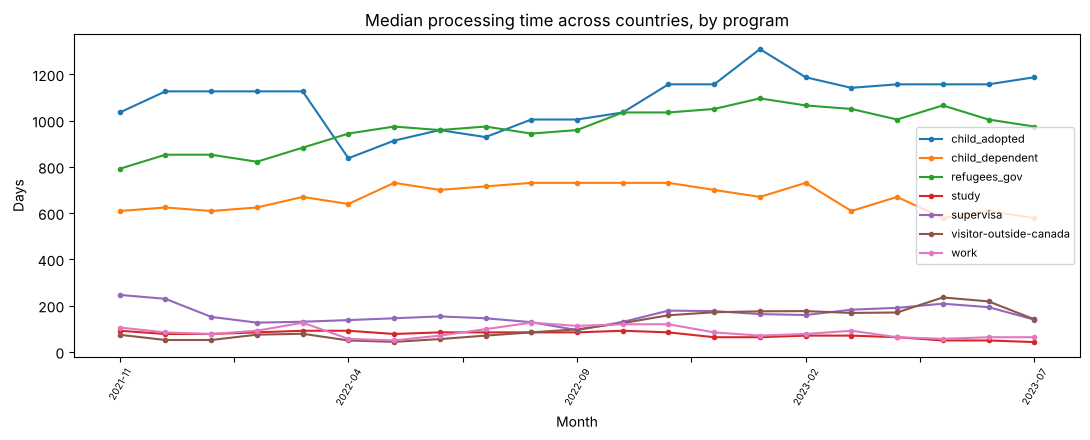

In [23]:
# 5.8 Aggregation: monthly median by program, with a chart
monthly_trend = main_df[main_df["status"] == "reported"].groupby(["year_month", "application_type"]).agg(
    countries_reported=("country", "nunique"),
    mean_days=("processing_days", "mean"),
    median_days=("processing_days", "median")).round(1).reset_index()

pivot = monthly_trend.pivot(index="year_month", columns="application_type", values="median_days")
pivot.plot(figsize=(11, 4.5), marker=".")
plt.title("Median processing time across countries, by program")
plt.xlabel("Month")
plt.ylabel("Days")
plt.xticks(rotation=60, fontsize=7)
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [24]:
# 5.9 Enrich the private-sponsorship table
priv_df["year_month"] = priv_df["snapshot_date"].dt.strftime("%Y-%m")
priv_df["total_months"] = priv_df["sponsor_months"] + priv_df["refugee_months"]   # only when both exist
priv_df = priv_df.sort_values(["country", "snapshot_date"]).reset_index(drop=True)
display(priv_df[priv_df["status"] == "both"].head())

,snapshot_date,country,sponsor_months,refugee_months,status,year_month,total_months
4806,2022-03-31,Egypt,10.0,29.0,both,2022-03,39.0
4807,2022-04-05,Egypt,11.0,27.0,both,2022-04,38.0
4808,2022-04-12,Egypt,11.0,27.0,both,2022-04,38.0
4809,2022-04-19,Egypt,11.0,27.0,both,2022-04,38.0
4810,2022-04-26,Egypt,11.0,27.0,both,2022-04,38.0


## 6. Validation Checks
Now I test the cleaned data. Each check prints `PASS` or `FAIL`.

In [25]:
results = []

def check(description, condition, extra=""):
    results.append({"check": description, "result": "PASS" if condition else "FAIL", "details": extra})

reported_rows = main_df["status"] == "reported"

# --- Missing values ---
check("No missing values in key columns (main)",
      main_df[["snapshot_date", "country", "application_type", "status"]].notna().all().all())
check("Reported rows all have processing_days",
      main_df.loc[reported_rows, "processing_days"].notna().all())
check("Non-reported rows have NO processing_days (blank only where status says so)",
      main_df.loc[~reported_rows, "processing_days"].isna().all(),
      f"{reported_rows.sum():,} reported, {(~reported_rows).sum():,} not reported")

# --- Duplicates ---
check("No duplicate program+date+country (main)",
      not main_df.duplicated(["application_type", "snapshot_date", "country"]).any())
check("No duplicate date+country (private)",
      not priv_df.duplicated(["snapshot_date", "country"]).any())

# --- Consistent representation ---
check("No HTML symbols in country names",
      not main_df["country"].str.contains("&").any())
check("Renamed countries use one name",
      not main_df["country"].isin(["Swaziland", "Turkey"]).any())
check("210 countries in both tables",
      main_df["country"].nunique() == 210 and priv_df["country"].nunique() == 210)
check("Every country appears on every date for every program",
      len(main_df) == 210 * main_df["snapshot_date"].nunique() * 7,
      f"{len(main_df):,} rows = 210 x {main_df['snapshot_date'].nunique()} dates x 7 programs")
units = main_df[reported_rows].groupby("application_type")["time_unit"].nunique()
check("Each program uses a single original unit", (units == 1).all())
check("Dates are real dates", str(main_df["snapshot_date"].dtype).startswith("datetime64"))

# --- Real-world sense ---
check("Processing times are all positive", (main_df.loc[reported_rows, "processing_days"] > 0).all())
max_days = main_df.loc[reported_rows, "processing_days"].max()
check("No processing time is longer than 5 years", max_days <= 5 * 365.25, f"longest = {max_days:.0f} days")
check("Dates are between Nov 2021 and today",
      main_df["snapshot_date"].between("2021-11-01", pd.Timestamp.today()).all(),
      f"{main_df['snapshot_date'].min().date()} to {main_df['snapshot_date'].max().date()}")
private_values = pd.concat([priv_df["sponsor_months"], priv_df["refugee_months"]]).dropna()
check("Private sponsorship times are between 1 and 120 months",
      private_values.between(1, 120).all(), f"min={private_values.min():.0f}, max={private_values.max():.0f}")
both = priv_df["status"] == "both"
check("total_months = sponsor + refugee",
      (priv_df.loc[both, "total_months"] == priv_df.loc[both, "sponsor_months"] + priv_df.loc[both, "refugee_months"]).all())

report = pd.DataFrame(results)
report.index = report.index + 1
display(report)
print(report["result"].value_counts().to_dict())

,check,result,details
1,No missing values in key columns (main),PASS,
2,Reported rows all have processing_days,PASS,
3,Non-reported rows have NO processing_days (bla...,PASS,"59,590 reported, 63,890 not reported"
4,No duplicate program+date+country (main),PASS,
5,No duplicate date+country (private),PASS,
6,No HTML symbols in country names,PASS,
7,Renamed countries use one name,PASS,
8,210 countries in both tables,PASS,
9,Every country appears on every date for every ...,PASS,"123,480 rows = 210 x 84 dates x 7 programs"
10,Each program uses a single original unit,PASS,


{'PASS': 16}


In [26]:
# A real-world sense check: summary per program, and the 5 longest waits
display(main_df[reported_rows].groupby("application_type")["processing_days"].describe().round(1))
display(main_df[reported_rows].nlargest(5, "processing_days")[
    ["application_type", "country", "snapshot_date", "time_value", "time_unit", "processing_days"]])

,count,mean,std,min,25%,50%,75%,max
application_type,,,,,,,,
child_adopted,280.0,1067.7,219.9,608.8,928.4,1126.2,1187.1,1674.1
child_dependent,1109.0,677.0,184.8,334.8,578.3,669.6,791.4,1156.6
refugees_gov,1512.0,826.4,404.7,30.4,547.9,974.0,1126.2,1521.9
study,15689.0,79.3,41.5,7.0,56.0,77.0,91.0,742.0
supervisa,9626.0,178.9,84.7,33.0,139.0,161.0,191.0,828.0
visitor-outside-canada,16468.0,132.3,116.8,5.0,52.0,99.0,174.0,1120.0
work,14906.0,100.2,67.4,7.0,63.0,84.0,119.0,693.0


,application_type,country,snapshot_date,time_value,time_unit,processing_days
80638,child_adopted,Nigeria,2023-07-06,55.0,month,1674.1
80639,child_adopted,Nigeria,2023-07-12,55.0,month,1674.1
23132,refugees_gov,Chad,2022-07-05,50.0,month,1521.9
23133,refugees_gov,Chad,2022-07-12,50.0,month,1521.9
23134,refugees_gov,Chad,2022-07-19,50.0,month,1521.9


The longest waits (for example, 1,120 days for a visitor visa) are real values from the 2022–23 backlog, not mistakes, so I keep them. If a unit had been misread (for example days as months) the numbers would be far bigger, and the 5-year check would catch it.

In [27]:
# Stop with an error if any check failed
assert (report["result"] == "PASS").all(), report[report["result"] == "FAIL"]
print("All checks passed!")

All checks passed!


## 7. Final Analytical Dataset

In [28]:
# Put the columns in a sensible order
processing_times = main_df[["snapshot_date", "year", "month", "year_month", "country", "application_type",
                            "program_group", "status", "time_value", "time_unit", "processing_days",
                            "processing_weeks", "wait_category", "rolling_avg_4", "change_vs_previous",
                            "median_all_countries", "days_above_median",
                            "country_avg_days", "days_vs_country_avg"]]

private_refugee = priv_df[["snapshot_date", "year_month", "country", "status",
                           "sponsor_months", "refugee_months", "total_months"]]

print("processing_times:", processing_times.shape)
display(processing_times[processing_times["status"] == "reported"].sample(10, random_state=7))

print("private_refugee:", private_refugee.shape)
display(private_refugee[private_refugee["status"] != "none"].sample(8, random_state=7))

processing_times: (123480, 19)


,snapshot_date,year,month,year_month,country,application_type,program_group,status,time_value,time_unit,processing_days,processing_weeks,wait_category,rolling_avg_4,change_vs_previous,median_all_countries,days_above_median,country_avg_days,days_vs_country_avg
38789,2023-02-23,2023,2,2023-02,Finland,work,Temporary resident,reported,3.0,week,21.0,3.0,1 month or less,21.0,0.0,77.0,-56.0,70.6,-49.6
62887,2022-12-14,2022,12,2022-12,Liechtenstein,work,Temporary resident,reported,12.0,week,84.0,12.0,1-3 months,87.5,-7.0,84.0,0.0,76.5,7.5
26362,2023-03-29,2023,3,2023-03,Congo,visitor-outside-canada,Temporary resident,reported,223.0,day,223.0,31.9,over 6 months,209.8,10.0,153.0,70.0,139.9,83.1
25860,2023-04-12,2023,4,2023-04,Comoros Island,work,Temporary resident,reported,9.0,week,63.0,9.0,1-3 months,80.5,-14.0,63.0,0.0,86.5,-23.5
78500,2022-09-28,2022,9,2022-09,New Caledonia,study,Temporary resident,reported,13.0,week,91.0,13.0,3-6 months,87.5,0.0,91.0,0.0,75.8,15.2
94360,2022-06-08,2022,6,2022-06,Senegal,study,Temporary resident,reported,6.0,week,42.0,6.0,1-3 months,42.0,0.0,84.0,-42.0,91.3,-49.3
96906,2022-12-06,2022,12,2022-12,Singapore,visitor-outside-canada,Temporary resident,reported,202.0,day,202.0,28.9,over 6 months,153.0,34.0,170.5,31.5,98.2,103.8
33293,2022-06-15,2022,6,2022-06,Ecuador,supervisa,Temporary resident,reported,151.0,day,151.0,21.6,3-6 months,151.0,0.0,151.0,0.0,168.5,-17.5
49685,2022-09-06,2022,9,2022-09,India,study,Temporary resident,reported,13.0,week,91.0,13.0,3-6 months,87.5,7.0,84.0,7.0,69.8,21.2
52246,2023-07-06,2023,7,2023-07,Ireland,visitor-outside-canada,Temporary resident,reported,244.0,day,244.0,34.9,over 6 months,285.8,-58.0,142.5,101.5,163.8,80.2


private_refugee: (17640, 7)


,snapshot_date,year_month,country,status,sponsor_months,refugee_months,total_months
16629,2023-06-22,2023-06,Uganda,both,16.0,33.0,49.0
16410,2022-06-21,2022-06,Türkiye,both,13.0,22.0,35.0
8602,2022-07-19,2022-07,Lebanon,both,24.0,40.0,64.0
11885,2022-09-06,2022-09,Pakistan,both,2.0,20.0,22.0
15533,2023-05-26,2023-05,Tajikistan,both,16.0,48.0,64.0
15498,2022-09-13,2022-09,Tajikistan,both,15.0,21.0,36.0
7813,2021-11-09,2021-11,Jordan,refugee_only,NaN,26.0,NaN
7292,2023-03-14,2023-03,Iran,sponsor_only,4.0,NaN,NaN


In [29]:
# Before vs after
comparison = pd.DataFrame({
    "raw": [len(raw), raw.duplicated(["type", "lastupdated", "country"]).sum(), raw["country"].nunique(),
            raw["country"].str.contains("&").sum(), "text"],
    "cleaned": [len(processing_times) + len(private_refugee),
                processing_times.duplicated(["application_type", "snapshot_date", "country"]).sum(),
                processing_times["country"].nunique(), 0, "datetime"]},
    index=["total rows", "duplicate keys", "distinct countries", "country names with HTML symbols", "date type"])
display(comparison)

print("Column types and missing values in the final main table:")
display(pd.DataFrame({"dtype": processing_times.dtypes.astype(str),
                      "missing": processing_times.isna().sum()}))

,raw,cleaned
total rows,184800,141120
duplicate keys,43664,0
distinct countries,212,210
country names with HTML symbols,1760,0
date type,text,datetime


Column types and missing values in the final main table:


,dtype,missing
snapshot_date,datetime64[us],0
year,int32,0
month,int32,0
year_month,str,0
country,str,0
application_type,str,0
program_group,str,0
status,str,0
time_value,float64,63890
time_unit,str,63890


In [30]:
# How much of each program actually has a reported time?
coverage = (processing_times.groupby("application_type")["status"]
            .value_counts(normalize=True).unstack().mul(100).round(1))
display(coverage)

status,not_enough_data,not_published,reported
application_type,,,
child_adopted,NaN,98.4,1.6
child_dependent,NaN,93.7,6.3
refugees_gov,75.0,16.4,8.6
study,NaN,11.1,88.9
supervisa,NaN,45.4,54.6
visitor-outside-canada,NaN,6.6,93.4
work,NaN,15.5,84.5


In [31]:
# Save the clean data
processing_times.to_csv("cic_processing_times_clean.csv", index=False)
private_refugee.to_csv("cic_private_refugee_times_clean.csv", index=False)
monthly_trend.to_csv("cic_monthly_trend.csv", index=False)
country_summary.to_csv("cic_country_summary.csv", index=False)
print("Saved 4 CSV files.")

Saved 4 CSV files.


### Why this dataset is ready for analysis
* **One row = one observation.** Each row in `processing_times` is one country, one program, one date. There are no duplicates.
* **Same unit everywhere.** All times are in days (`processing_days`), so programs and countries can be compared fairly. The original value and unit are kept too.
* **Missing values are explained.** The `status` column shows whether a time is `reported`, `not_enough_data`, or `not_published`. Filter on `status == "reported"` for rows with numbers.
* **Consistent names and types.** HTML symbols are gone, renamed countries use one name, and dates are real dates.
* **Extra columns for analysis.** Year/month, wait categories, rolling averages, change since last snapshot, and comparisons to the median and to each country's own average.
* **Private sponsorship is a separate table** because it reports two different times in months.

**Limitations:** converting months to days is approximate (30.4375 days per month). I assumed sponsor/refugee times are months. Some programs have little data: government-assisted refugees are about 75% "Not enough data" and the child programs are more than 90% unpublished.

## References
* ayraza. *Canada Visa Processing Time (last updated July 23)* [Data set]. Kaggle. https://www.kaggle.com/datasets/ayraza/canada-visa-processing-time-last-updated-july-23?select=processed_cic_data.csv
* The values in the data are IRCC (Immigration, Refugees and Citizenship Canada) published processing-time estimates, collected and shared by the Kaggle dataset author above.